# Principal Component Analysis


Principal Component Analysis using the five-point dataset from the seminar slides.

## What does PCA do?
PCA transforms the original variables into new directions called principal components. The first component (PC1) captures the greatest possible variance. PCA can help reduce the number of variables while retaining much of the information.

## Create the dataset

We have five observations and two variables, `X` and `Y`. The values match the seminar dataset.

In [1]:
# Create the dataset
data <- data.frame(
  X = c(2, 3, 4, 5, 6),
  Y = c(1, 5, 3, 6, 5)
)

print(data)

  X Y
1 2 1
2 3 5
3 4 3
4 5 6
5 6 5



- `data.frame()` creates a table.
- `c(...)` combines values into a vector.
- `X` and `Y` are the two variables.
- Each row is one observation (data point).

## Center the data

PCA usually starts by subtracting each variable's mean from its values. This moves the data so each variable has mean zero.

In [2]:
centered_data <- scale(data, center = TRUE, scale = FALSE)

print(centered_data)
colMeans(centered_data)  # should be 0, apart from tiny rounding error

      X  Y
[1,] -2 -3
[2,] -1  1
[3,]  0 -1
[4,]  1  2
[5,]  2  1
attr(,"scaled:center")
X Y 
4 4 


X Y 
0 0

- `scale()` can center and/or standardize columns.
- `center = TRUE` subtracts each column's mean.
- `scale = FALSE` means do not divide by the standard deviation.
- Here, both means are 4, so the centered values are `X - 4` and `Y - 4`.

## Calculate the covariance matrix

The covariance matrix describes each variable's variance and how the two variables vary together.

In [3]:
cov_matrix <- cov(centered_data)

print(cov_matrix)

     X    Y
X 2.50 2.25
Y 2.25 4.00


- `cov()` calculates sample covariance, dividing by `n - 1` (here, 4).
- The diagonal entries are variances: Var(X) = 2.5 and Var(Y) = 4.
- The off-diagonal entries are covariance: Cov(X, Y) = 2.25.
- Positive covariance means X and Y tend to increase together.

## Find eigenvalues and eigenvectors

Eigenvalues tell us how much variance is associated with each principal component. Eigenvectors give the directions of those components.

In [4]:
result <- eigen(cov_matrix)

print(result$values)   # eigenvalues
print(result$vectors)  # eigenvectors are stored in columns

[1] 5.6217082 0.8782918
          [,1]       [,2]
[1,] 0.5847103 -0.8112422
[2,] 0.8112422  0.5847103


- `eigen()` calculates the eigenvalues and eigenvectors of the covariance matrix.
- The first eigenvalue is the largest, so its eigenvector gives PC1.
- For this dataset, the eigenvalues are approximately 5.62 and 0.88.
- Eigenvector signs can differ from the slides; flipping an eigenvector's sign is mathematically equivalent.

##  Project the centered data onto PC1

Projection turns each two-variable observation into a single PC1 score.

In [5]:
pc1 <- centered_data %*% result$vectors[, 1]

print(round(pc1, 2))

      [,1]
[1,] -3.60
[2,]  0.23
[3,] -0.81
[4,]  2.21
[5,]  1.98


- `result$vectors[, 1]` selects the first eigenvector (PC1 direction).
- `%*%` performs matrix multiplication.
- Each score is the dot product of the centered `(X, Y)` values and the PC1 direction.
- The sign of all scores may be reversed if R returns the opposite but equivalent eigenvector direction.

## Calculate explained variance

Explained variance tells us the percentage of total variance captured by each component.

In [6]:
explained_variance <- result$values / sum(result$values) * 100

print(round(explained_variance, 2))

[1] 86.49 13.51


- `sum(result$values)` is the total variance (the sum of eigenvalues), approximately 6.5.
- Divide each eigenvalue by the total and multiply by 100.
- PC1 explains about 86.5% of the variance; PC2 explains about 13.5%.
- Keeping PC1 reduces the data from two dimensions to one while retaining about 86.5% of the variance.

## Plot the original data

A scatter plot displays the five observations using their original X and Y values.

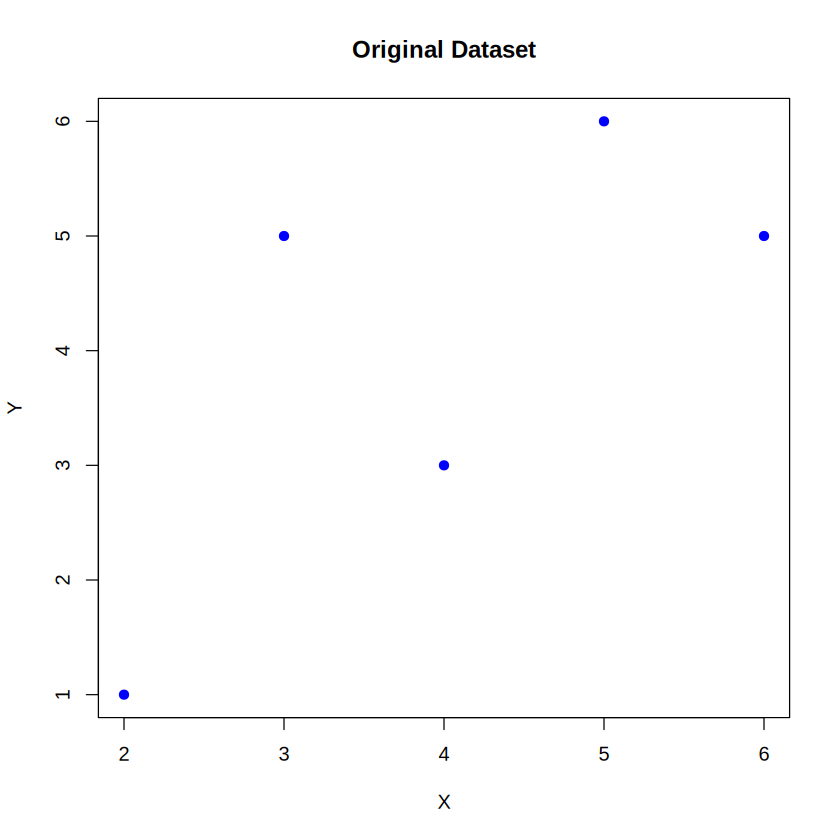

In [7]:
plot(data$X, data$Y,
     main = "Original Dataset",
     xlab = "X",
     ylab = "Y",
     pch = 19,
     col = "blue")

- `data$X` selects the X column; `data$Y` selects the Y column.
- `plot()` creates the graph.
- `main`, `xlab`, and `ylab` set the title and axis labels.
- `pch = 19` uses filled circles; `col = "blue"` colors the points blue.

## Step 8 — Plot the PC1 scores

This plot places each observation on a one-dimensional PC1 axis.

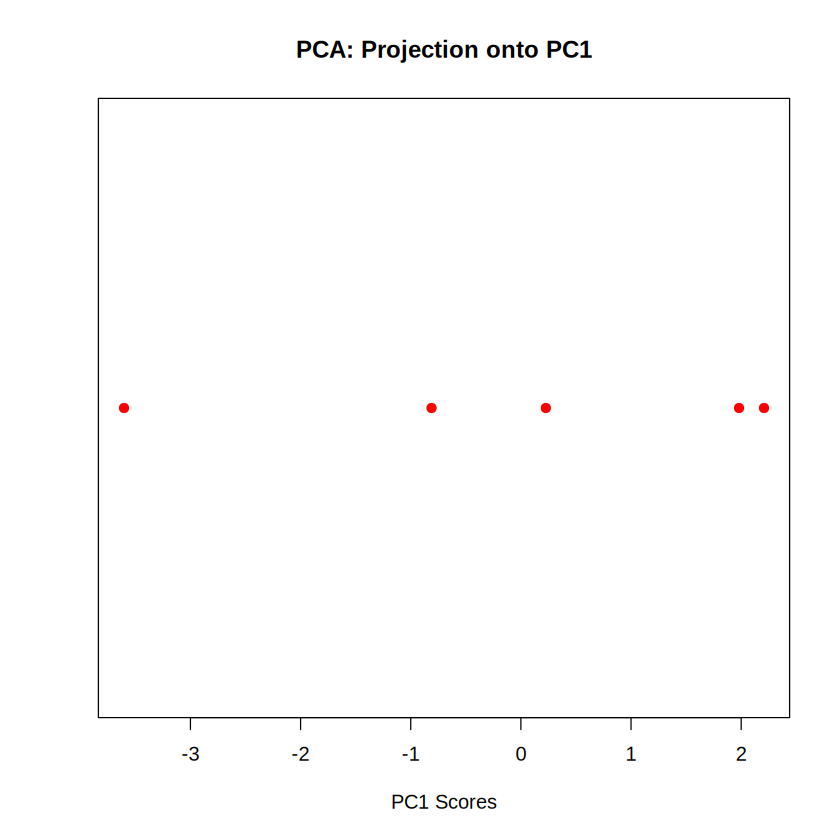

In [8]:
plot(as.numeric(pc1), rep(0, length(pc1)),
     main = "PCA: Projection onto PC1",
     xlab = "PC1 Scores",
     ylab = "",
     yaxt = "n",
     pch = 19,
     col = "red")

- `as.numeric(pc1)` converts the score matrix to a numeric vector for plotting.
- `rep(0, length(pc1))` gives every point the same vertical coordinate, zero.
- `yaxt = "n"` hides the unnecessary y-axis labels.
- The horizontal position shows each observation's PC1 score.